In [1]:
import pandas as pd

titanic_df = pd.read_csv("titanic-data.csv")

titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## inserting and Deleting Column and rows

In [2]:
# Dropping a column
# dataframe.drop(<column_name>, axis)
# axis : {0 or 'index', 1 or 'columns'}, default 0
#     Whether to drop labels from the index (0 or 'index') or columns (1 or 'columns')

titanic_df.drop("PassengerId", axis = 1, inplace=True)

In [3]:
titanic_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.drop([0,2,5], axis = 0, inplace=False).head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S


In [5]:
# Inserting a column

last_names = [name.split(",")[0] for name in titanic_df["Name"]]

# last_names = list(
#     map(lambda x : x.split(",")[0] , titanic_df.Name)
# )

titanic_df["last_name"] = last_names

In [6]:
titanic_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,last_name
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Futrelle
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Allen


In [7]:
import pandas as pd

# assume titanic_df is already loaded with the classic 12 columns
new_row = {
    "Survived": 0,
    "Pclass": 3,
    "Name": "Braund, Mr. Owen Harris",
    "Sex": "male",
    "Age": 22.0,
    "SibSp": 1,
    "Parch": 0,
    "Ticket": "A/5 21171",
    "Fare": 7.25,
    "Cabin": None,          # or "a" if you really want that
    "Embarked": "S"
}

# Recommended modern way
titanic_df = pd.concat([titanic_df, pd.DataFrame([new_row])], ignore_index=True)

# Or if you insist on a specific index label:
titanic_df.loc[900] = new_row          # works when the dict keys match column names
titanic_df.tail()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,last_name
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S,Johnston
889,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C,Behr
890,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q,Dooley
891,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,None,S,NaN
900,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,None,S,NaN


## Handling Nan or Null values

In [8]:
titanic_df.isna().sum()

Survived       0
Pclass         0
Name           0
Sex            0
Age          177
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin        689
Embarked       2
last_name      2
dtype: int64

In [9]:
# Removing null values
titanic_df_filter = titanic_df.dropna(subset = "Embarked", axis = 0, how = "all", ignore_index = True)

In [10]:
titanic_df_filter.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,last_name
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Futrelle
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Allen


29.677611731843573


<Axes: ylabel='Frequency'>

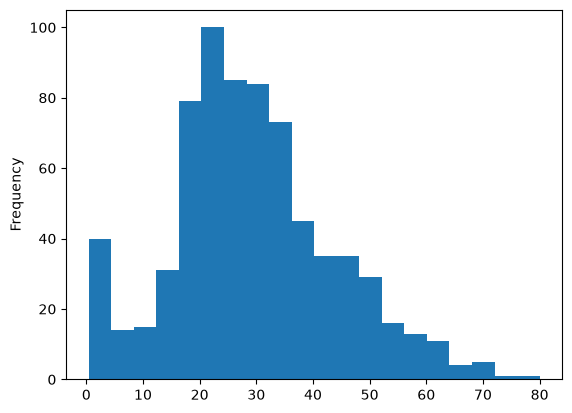

In [11]:
print(titanic_df.Age.mean())
titanic_df.Age.plot.hist(bins = 20)

In [12]:
mean_age = titanic_df.Age.mean()

In [13]:
titanic_df["Age"] = titanic_df["Age"].fillna(mean_age)

In [14]:
titanic_df.isna().sum()

Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin        689
Embarked       2
last_name      2
dtype: int64

<Axes: ylabel='Frequency'>

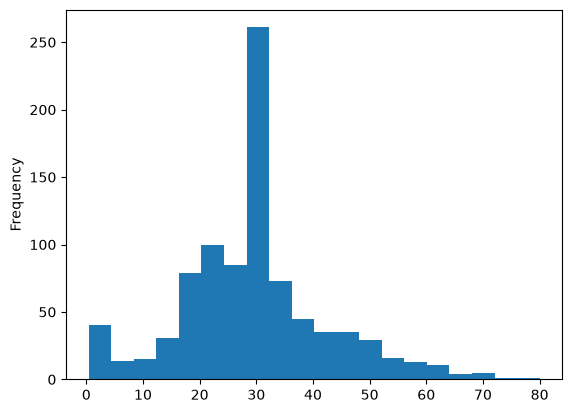

In [15]:
titanic_df.Age.plot.hist(bins = 20)

## Imputation of Age column w.r.t gender provided.

In [18]:
titanic_df_2 = pd.read_csv("titanic-data.csv")

In [19]:
mean_ages = titanic_df_2.groupby("Sex")["Age"].transform("mean")

In [20]:
titanic_df_2["Age"].fillna(mean_ages, inplace=True)

C:\Users\Acer\AppData\Local\Temp\ipykernel_1416\3471555883.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  titanic_df_2["Age"].fillna(mean_ages, inplace=True)


0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    27.915709
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64

<Axes: ylabel='Frequency'>

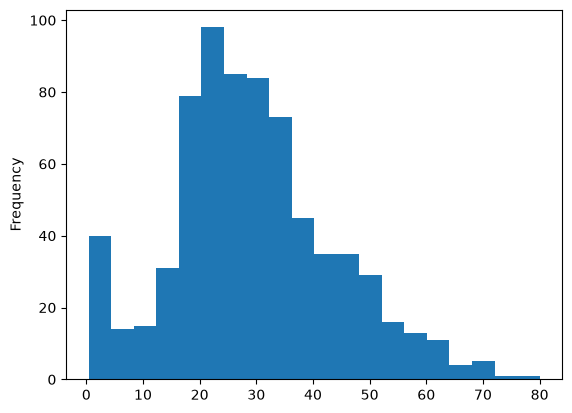

In [21]:
titanic_df_2.Age.plot.hist(bins = 20)

In [22]:
# Feature From Null Vlaues

In [23]:
titanic_df.Cabin

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
888     NaN
889    C148
890     NaN
891    None
900    None
Name: Cabin, Length: 893, dtype: object

In [24]:
titanic_df.Cabin = titanic_df.Cabin.notna().astype(int) # .transform(lambda x: "Yes" if x else "No")

In [25]:
titanic_df.isna().sum()

Survived     0
Pclass       0
Name         0
Sex          0
Age          0
SibSp        0
Parch        0
Ticket       0
Fare         0
Cabin        0
Embarked     2
last_name    2
dtype: int64

<Axes: >

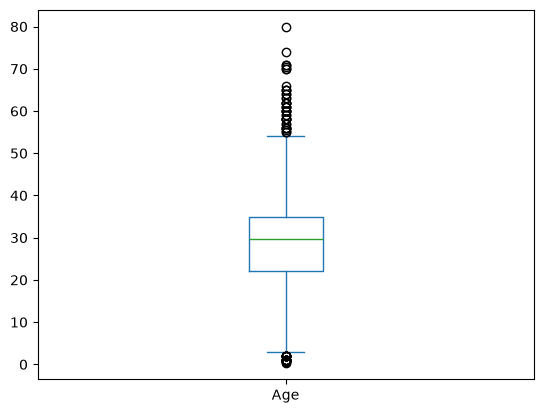

In [26]:
titanic_df.Age.plot.box()

## Handling Null value for Age, using initials (Mr., Miss or Master)groups.

## Cleaning Duplicates